# Работа с текстовыми данными в torchtext и torchdata. PyTorch Advanced

На этом занятии мы познакомимся с библиотекой PyTorch, которая предоставляет удобный API для загрузки и подготовке кастомных наборов данных. Также мы расширим имеющиеся знания библиотеки PyTorch.

## Часть 1. Загрузка и подготовка данных средствами torchtext и torchdata

### Загрузка данных из нескольких файлов

В старых версиях библиотека torchtext отвечала за все операции по подготовке текстовых данных (начиная с загрузки и парсинга файлов csv и др. и заканчивая применением трансформаций и т. д.). В настоящее время в библиотеке находятся исключительно инструменты для обработки текста, готовые датасеты и модели.

Весь старый функционал при этом доступен в пакете torchtext.legacy, но мы им пользоваться не будем. Вместо этого мы откроем для себя еще один модуль PyTorch, который называется torchdata.

In [1]:
import torchtext
import torchdata
torchtext.__version__, torchdata.__version__

('0.15.2+cpu', '0.6.1')

In [2]:
from torchtext import transforms
from torchdata import datapipes

Приступим к загрузке первого простого набора данных (предположим, что мы решаем задачу бинарной классификации).

In [3]:
def print_simple_data_pipe(date_pipe: datapipes.iter.IterDataPipe) -> None:
  print(type(date_pipe))
  for sample in data_pipe:
    print(sample)

In [4]:
# создаем IterDataPipe с именами файлов (можем подгружать данные из нескольких файлов)
data_pipe = datapipes.iter.IterableWrapper(['data1.csv', 'data2.csv'])
print_simple_data_pipe(data_pipe)

<class 'torch.utils.data.datapipes.iter.utils.IterableWrapperIterDataPipe'>
data1.csv
data2.csv


In [5]:
# открываем каждый файл
data_pipe = datapipes.iter.FileOpener(data_pipe, mode='r', encoding='utf-8')
print_simple_data_pipe(data_pipe)

<class 'torch.utils.data.datapipes.iter.fileopener.FileOpenerIterDataPipe'>
('data1.csv', StreamWrapper<<_io.TextIOWrapper name='data1.csv' mode='r' encoding='utf-8'>>)
('data2.csv', StreamWrapper<<_io.TextIOWrapper name='data2.csv' mode='r' encoding='utf-8'>>)


In [6]:
# парсим каждый файл как csv
data_pipe = data_pipe.parse_csv(skip_lines=0, delimiter=',', as_tuple=True)
print_simple_data_pipe(data_pipe)

<class 'torchdata.datapipes.iter.util.plain_text_reader.CSVParserIterDataPipe'>
('I love you', '1')
('You are stupid', '0')
('I hate you', '0')
('My beautiful love', '1')
('Great job', '1')
('Badboy', '0')


Таким образом, модуль torchdata позволяет нам удобно загружать наборы данных.

Далее мы можем создать функции для токенизации. В данном случае у нас английский язык и нет знаков препинания, поэтому воспользуемся простым методом split(). Для более сложных случаев используются NLTK, razdel и др.

In [7]:
def tokenize(text: str) -> list[str]:
  # здесь может быть более сложная логика токенизации с использованием различных инструментов
  # также именно здесь обычно проводится нормализация токенов и удаление стоп слов
  # потому что словарь далее будет формироваться для тех токенов, которые останутся

  # в задачах машинного перевода и генерации мы обычно не приводим к нижнему регистру
  return [t.lower() for t in text.split()]

### Формирование словарей

Для формирования словаря нам необходимо обернуть нашу токенизацию в итератор

In [8]:
def yield_tokens(data_iter: datapipes.iter.IterDataPipe):
  # итерируемся по набору данных
  for example, label in data_iter:
    yield tokenize(example)

Теперь давайте построим вокабуляр с помощью torchtext

In [9]:
from torchtext.vocab import build_vocab_from_iterator

In [10]:
vocab = build_vocab_from_iterator(
    yield_tokens(data_pipe),
    min_freq=2,
    specials= ['<pad>', '<sos>', '<eos>', '<unk>'],
    special_first=True
)
# если мы попытаемся получить индекс слова, которого не знаем - вернется индекс для токена <unk>
vocab.set_default_index(vocab['<unk>'])

In [11]:
vocab['me'], vocab['<unk>']

(3, 3)

In [12]:
# потому что min_freq=2
vocab['hate']

3

In [13]:
vocab['you']

4

In [14]:
vocab.get_stoi()

{'i': 5, 'love': 6, 'you': 4, '<unk>': 3, '<eos>': 2, '<sos>': 1, '<pad>': 0}

In [15]:
vocab.get_itos()

['<pad>', '<sos>', '<eos>', '<unk>', 'you', 'i', 'love']

При решении задачи машинного перевода нам потребовалось бы создание двух словарей.

### Нумеризация токенов в документах

Очень часто мы используем слой Embedding в PyTorch, для его использования нам необходимо представить документ в виде последовательности числовых индексов (которые соответствуют индексам слов в словарях).

In [16]:
from torchtext import transforms

In [17]:
def vocab_transform(vocab: torchtext.vocab.Vocab) -> transforms.Sequential:
    text_tranform = transforms.Sequential(
        transforms.VocabTransform(vocab=vocab),
        # добавляем в начало и конец документа индексы токенов <sos> и <eos> соответственно
        # это актуально для решения задач машинного перевода и генерации текстов
        # для решения условной задачи классификации это избыточно
        transforms.AddToken(vocab['<sos>'], begin=True),
        transforms.AddToken(vocab['<eos>'], begin=False)
    )
    return text_tranform

In [18]:
l = list(data_pipe)
e = l[3][0]

In [19]:
e

'My beautiful love'

In [20]:
t = vocab_transform(vocab)(tokenize(e))

In [21]:
i2w = vocab.get_itos()
for index in t:
    print(i2w[index], end=' ')

<sos> <unk> <unk> love <eos> 

Если у вас мало данных - добавляйте в словарь все слова, чтобы не было такой ситуации :)

Применим трансформацию ко всем документам в наборе данных

In [22]:
def apply_vocab_transform(pair: tuple[list[str], int]) -> tuple[list[int], int]:
    return (
        vocab_transform(vocab)(tokenize(pair[0])),
        int(pair[1])
    )

In [23]:
data_pipe = data_pipe.map(apply_vocab_transform)

In [24]:
l = list(data_pipe)
l[4], l[1]

(([1, 3, 3, 2], 1), ([1, 4, 3, 3, 2], 0))

### Создание батчей

In [25]:
data_pipe = data_pipe.bucketbatch(
    batch_size = 2,
    use_in_batch_shuffle=False
)

In [26]:
print(list(data_pipe))

[[([1, 3, 3, 2], 1), ([1, 5, 6, 4, 2], 1)], [([1, 3, 2], 0), ([1, 5, 3, 4, 2], 0)], [([1, 4, 3, 3, 2], 0), ([1, 3, 3, 6, 2], 1)]]


In [27]:
# обратите внимание - здесь на входе уже коллекция батчей!
def separate(pair: list[tuple[list[int], int]]) -> list[tuple[tuple[list[int],], tuple[int,]]]:
    examples, targets = zip(*pair)
    return examples, targets

data_pipe = data_pipe.map(separate)

In [28]:
print(list(data_pipe))

[(([1, 5, 6, 4, 2], [1, 3, 3, 2]), (1, 1)), (([1, 3, 2], [1, 4, 3, 3, 2]), (0, 0)), (([1, 5, 3, 4, 2], [1, 3, 3, 6, 2]), (0, 1))]


Сделаем padding последовательностей - чтобы все последовательности были одной длины (дополним все последовательности индексом токена pad).

In [29]:
def apply_padding(pair):
    return (transforms.ToTensor(vocab['<pad>'])(list(pair[0])),pair[1])

data_pipe = data_pipe.map(apply_padding)

In [30]:
print(list(data_pipe))

[(tensor([[1, 5, 3, 4, 2],
        [1, 5, 6, 4, 2]]), (0, 1)), (tensor([[1, 4, 3, 3, 2],
        [1, 3, 3, 2, 0]]), (0, 1)), (tensor([[1, 3, 3, 6, 2],
        [1, 3, 2, 0, 0]]), (1, 0))]


In [31]:
list(data_pipe)[0][0].shape

torch.Size([2, 5])

Каждый батч представляет собой кортеж, состоящий из 3 (количество батчей) пар <тензор, кортеж). Каждый тензор имеет размерность (2, 5), 2 - размер батча, 5 - количество элементов последовательности.

## Часть 2. Сборка и обучение модели

Собираем простую модель.

In [32]:
import torch.nn as nn

class ClassificationModel(nn.Module):
    def __init__(self, input_dim, embedding_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, embedding_dim)
        self.gru = nn.GRU(embedding_dim, hidden_dim, 1, batch_first=True)
        self.gru2 = nn.GRU(hidden_dim, hidden_dim, 1, batch_first=True)
        self.gru3 = nn.GRU(hidden_dim, hidden_dim, 1, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, text):
        embedded = self.embedding(text)
        output, hidden = self.gru(embedded)
        output, hidden = self.gru2(output)
        output, hidden = self.gru3(output)
        return self.fc(hidden.squeeze(0))

In [33]:
len(vocab)

7

Создаем экземпляр класса, устанавливаем параметры.

In [34]:
model = ClassificationModel(len(vocab), 64, 32)

Таким образом мы получаем выход последнего output (конечное состояние.)

In [35]:
list(data_pipe)[0]

(tensor([[1, 3, 3, 6, 2],
         [1, 5, 6, 4, 2]]),
 (1, 1))

In [36]:
model(list(data_pipe)[0][0])

tensor([[0.0022],
        [0.0103]], grad_fn=<AddmmBackward0>)

In [37]:
list(data_pipe)[0][1]

(0, 1)

Мы не используем сигмоид, используем только логиты на выходе. Воспользуемся функцией потерь, которая сама будет считать сигмоиды и бинарную перекрестную энтропию.

In [38]:
criterion = nn.BCEWithLogitsLoss()

In [39]:
import torch.optim as optim

optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [40]:
import torch

Обучаем модель.

In [41]:
import matplotlib.pyplot as plt

In [101]:
import time
start_time = time.time()

losses = []

for i in range (100):

  for batch in data_pipe:
    pred = model(batch[0]).squeeze(1)
    target = torch.Tensor(batch[1])
    loss = criterion(pred, target)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()
    losses.append(loss.item())

# время в секундах
time.time() - start_time

2.4272916316986084

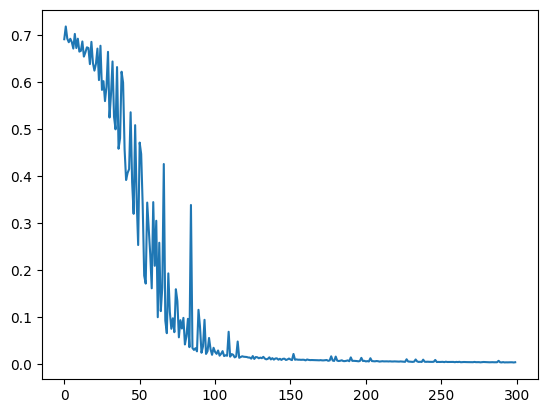

In [43]:
plt.plot(losses)

Видим, что функция потерь уменьшается -> обучение идет.

## Часть 3. Использование CUDA (GPU)

Я специально усложнил описанную выше модель для классификации - сделал стек из трех GRU. 100 эпох обучения уже занимают несколько секунд. Обучение в данный момент производится на CPU. Давайте попробуем выполнить его на GPU.

Включим окружение с GPU (Graphics Processor Unit), не с TPU.

Первым делом проверим, доступна ли нам CUDA (Compute Unified Device Architecture).

In [44]:
torch.cuda.is_available()

True

CUDA доступна, значит мы можем использовать для вычислений графический процессор.

In [48]:
torch.cuda.get_device_name(), torch.cuda.get_device_properties(torch.cuda.current_device)

('Tesla T4',
 _CudaDeviceProperties(name='Tesla T4', major=7, minor=5, total_memory=15101MB, multi_processor_count=40))

По умолчанию все создаваемые тензоры располагаются в оперативной памяти.

In [50]:
a = torch.ones(400, 300, 3000)
b = torch.ones(400, 300, 3000) * 3

Но мы в любой момент можем их перенести в видеопамять.

In [52]:
a = a.to('cuda')

In [53]:
a

tensor([[[1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         ...,
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.]],

        [[1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         ...,
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.]],

        [[1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         ...,
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.]],

        ...,

        [[1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         ...,
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1., 

Или сразу же можно создать тензор в видеопамяти

In [55]:
c = torch.ones(300, 200, device='cuda')
c

tensor([[1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        ...,
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.]], device='cuda:0')

In [57]:
c = c.to('cpu')
c

tensor([[1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        ...,
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.]])

Очень часто в репозиториях с кодом на PyTorch можно увидеть следующую строчку (или что-то похожее).

In [58]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

Благодаря этой строке, можно автоматически сразу же создавать тензоры и другие объекты на доступном устройстве.

В данном случае CUDA доступна.

In [59]:
device

device(type='cuda')

Сейчас тензор a находится в видеопамяти, а тензор b - в оперативной памяти. Действия над такими тензорами невозможны!

In [61]:
a * b

RuntimeError: ignored

In [62]:
a = a.to('cpu')

In [66]:
start_time = time.time()
a * b
time.time() - start_time

0.9014544486999512

In [67]:
a = a.to(device)
b = b.to(device)

In [70]:
start_time = time.time()
a * b
time.time() - start_time

0.0009989738464355469

Мягко говоря, использовать видеокарту для выполнения операций с тензорами **куда (то есть CUDA) рациональнее!**

Вспомним, что у нас есть модель. Создадим новый экземпляр.

In [72]:
model2 = ClassificationModel(len(vocab), 64, 32)
print(model)

ClassificationModel(
  (embedding): Embedding(7, 64)
  (gru): GRU(64, 32, batch_first=True)
  (gru2): GRU(32, 32, batch_first=True)
  (gru3): GRU(32, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


Сейчас все тензоры с весами расположены в оперативной памяти. Перенесем их в видеопамять.

In [73]:
model2 = model2.to(device)

Снова выполним обучение модели.

In [106]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model2.parameters(), lr=1e-3)

In [110]:
start_time = time.time()

losses = []

for i in range (100):

  for batch in data_pipe:
    pred = model2(batch[0].to(device)).squeeze(1)
    target = torch.Tensor(batch[1]).to(device)
    loss = criterion(pred, target)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()
    losses.append(loss.item())

# время в секундах
time.time() - start_time

1.011753797531128

По-хорошему следовало бы в ходе применений трансформаций на этапе предобработки сразу же помещать тензоры в видеопамять. Процесс перемещения тензоров также занимает время, однако даже так мы видим выигрыш от использования графического процессора.

Если вы работаете в Colab, обязательно попробуйте использовать видеокарту при обучении ваших моделей.

## Часть 4. Инициализация весов начальными значениями

По умолчанию при создании слоев моделей PyTorch они инициализируются по-разному (можно в любой момент уточнить в документации). В виду того, что при решении задачи оптимизации (минимизация функции потерь) начальные значения параметров могут сыграть важную роль, нам необходимо научиться брать под контроль инициализацию весов.

Немного упростим имеющуюся модель.

In [111]:
class ClassificationModel2(nn.Module):
    def __init__(self, input_dim, embedding_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, embedding_dim)
        self.gru = nn.GRU(embedding_dim, hidden_dim, 1, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, text):
        embedded = self.embedding(text)
        output, hidden = self.gru(embedded)
        return self.fc(hidden.squeeze(0))

In [112]:
model3 = ClassificationModel2(len(vocab), 64, 32)

В любой момент мы можем посмотреть текущие значения весов и сдвигов.

In [116]:
for name, param in model3.gru.named_parameters():
  print(f'{name}: {param}')

weight_ih_l0: Parameter containing:
tensor([[ 0.0982,  0.0869,  0.0831,  ...,  0.0763, -0.0013, -0.0997],
        [-0.0132, -0.0085,  0.1354,  ...,  0.1468,  0.0867, -0.0071],
        [-0.0944, -0.0170,  0.1640,  ..., -0.0592,  0.1043, -0.1658],
        ...,
        [-0.0785, -0.0793,  0.1446,  ...,  0.0646,  0.1245, -0.1224],
        [ 0.0742, -0.0059,  0.1133,  ..., -0.1196, -0.1310, -0.0994],
        [-0.0567, -0.0588, -0.1733,  ..., -0.1712, -0.1261,  0.1684]],
       requires_grad=True)
weight_hh_l0: Parameter containing:
tensor([[ 0.0215, -0.0613,  0.1217,  ..., -0.0291,  0.0309, -0.1440],
        [ 0.0492, -0.0728, -0.0267,  ..., -0.0436, -0.1448, -0.0843],
        [ 0.1091, -0.1515,  0.0368,  ..., -0.0213,  0.0103,  0.0852],
        ...,
        [ 0.1574, -0.1139, -0.0382,  ..., -0.0713,  0.0879,  0.0062],
        [-0.0688,  0.0488, -0.1673,  ..., -0.0255,  0.0417,  0.0609],
        [ 0.0181,  0.1414,  0.0183,  ..., -0.1094, -0.0384,  0.0493]],
       requires_grad=True)
bias_i

In [119]:
d = {}

for name, param in model3.fc.named_parameters():
  print(f'{name}: {param}')
  d[name] = param

weight: Parameter containing:
tensor([[-0.1407, -0.0871,  0.0266, -0.1121,  0.0641, -0.0503,  0.0976,  0.0947,
         -0.0166, -0.1610, -0.0546,  0.0554,  0.1011,  0.1549, -0.0448,  0.0517,
          0.0135, -0.1397,  0.0641, -0.0336, -0.1750, -0.0362, -0.1763, -0.0885,
         -0.0671,  0.0561, -0.0204,  0.0583,  0.0314,  0.1219, -0.0476, -0.0263]],
       requires_grad=True)
bias: Parameter containing:
tensor([-0.1638], requires_grad=True)


Инициализируем значения весов параметризованным нормальным распределением.

In [120]:
torch.nn.init.normal_(d['weight'], 50, 15)

Parameter containing:
tensor([[68.5340, 36.6901, 25.9722, 68.0407, 58.9480, 41.0384, 56.3966, 56.0068,
         38.6534, 39.8704, 73.1682, 59.7562, 57.2848, 33.3442, 57.8592, 50.4531,
         58.2650, 56.4556, 61.9258, 57.7793, 44.9740, 79.1165, 49.3835, 36.4248,
         40.6246, 65.5758, 34.7544, 52.6514, 28.0405, 44.1241, 46.7821, 32.1836]],
       requires_grad=True)

In [121]:
for name, param in model3.fc.named_parameters():
  print(f'{name}: {param}')
  d[name] = param

weight: Parameter containing:
tensor([[68.5340, 36.6901, 25.9722, 68.0407, 58.9480, 41.0384, 56.3966, 56.0068,
         38.6534, 39.8704, 73.1682, 59.7562, 57.2848, 33.3442, 57.8592, 50.4531,
         58.2650, 56.4556, 61.9258, 57.7793, 44.9740, 79.1165, 49.3835, 36.4248,
         40.6246, 65.5758, 34.7544, 52.6514, 28.0405, 44.1241, 46.7821, 32.1836]],
       requires_grad=True)
bias: Parameter containing:
tensor([-0.1638], requires_grad=True)


Равномерное с параметрами.

In [122]:
torch.nn.init.uniform_(d['weight'], 10, 30)

Parameter containing:
tensor([[15.8610, 13.1766, 18.6941, 15.8815, 23.6147, 21.7449, 17.8419, 26.8263,
         21.5186, 18.6066, 29.8289, 17.2742, 10.7066, 26.3845, 20.8589, 18.9788,
         11.7376, 13.7279, 11.2149, 16.7415, 28.4889, 12.2090, 26.9326, 28.5821,
         10.7404, 22.8831, 28.7991, 10.6868, 25.3677, 17.2857, 22.8194, 14.3576]],
       requires_grad=True)

Все возможные варианты инициализации весов можно посмотреть [здесь](https://pytorch.org/docs/stable/nn.init.html).

Особое внимание рекомендую обратить на нормальное и равномерное распределения Ксавьера. Эти распределения изначально были предложены для использования при обучении нейронных сетей.

Также обращаю внимание, что при инициализации значений весов с помощью распределения Ксавьера сами значения из распределения умножаются на некоторый масштабирующий коэффициент (gain). Он определяется функцией активации слоя и определяется по формулам из статьи выше.

## Часть 5. Динамическое изменение скорости обучения. Использование шедулеров

Нейронные сети обучаются градиентными методами. Основная проблема градиентных методов - отсутствие гарантии застревания в локальном минимуме целевой функции.

Обучение моделей, как правило, заканчивается тогда, когда функция потерь перестает значительно уменьшаться. Но значит ли это, что достигнут глобальный минимум?

Основным параметром любого градиентного метода является скорость обучения (learning rate). В простых случаях - это и есть величина шага. В более сложных (оптимизаторы Adam, RMSProp и т .д.) - это параметр, на основе которого вычисляется величина шага в данный момент времени. Но learning rate всегда прямо пропорционален размеру шага!

Общей стратегией повышения качества обучения является установка некоторого относительно небольшого значения скорости обучения и постепенное его уменьшение в процессе обучения. Таким образом, первые шаги будут относительно большими, в то время как к концу обучения мы будем делать мелкие шаги, чтобы не вылететь из окрестности потенциальной точки минимума.

При этом не стоит забывать, что такая точка минимум не обязательно является точкой глобального минимум. Может быть, из нее наоборот разумно выпрыгнуть и попробовать пойти в другом направлении, к другой локальной точке минимума, которая может находиться ближе кточке глобального минимума (или даже являться ей).

Как прикладные математики и опытные пользователи PyTorch мы должны уметь контролировать и изменять скорость обучения в процессе оптимизации.

In [135]:
model4 = ClassificationModel2(len(vocab), 64, 32)

In [136]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model4.parameters(), lr=1e-1)

Итак, мы задали начальное значение скорости обучения. Давайте рассмотрим концепцию шедулеров, которая позволит нам менять значение learning rate в ходе обучения. PyTorch предоставляет нам множество заранее подготовленных шедулеров с разной стратегией изменения скорости обучения. Посмотрим сначала на наиболее базовый вариант.

In [137]:
# зададим собственную функцию для изменения скорости обучения (на эту функцию будем умножаться начальное значение lr)
l = lambda epoch: 0.7 ** epoch
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=l)

In [153]:
lrs = []

Важно понимать, что для шедулера номер эпохи - это не обязательно номер текущей эпохи обучения. По сути это счетчик, который мы в любой момент можем увеличить (например, уменьшать lr после обработки очередного батча).

In [155]:
for i in range(5):
  # это одна эпоха
  for j in range(3):
    # но у шедулера свой счетчик
    scheduler.step()
    optimizer.step()
    lrs.append(optimizer.param_groups[0]["lr"])

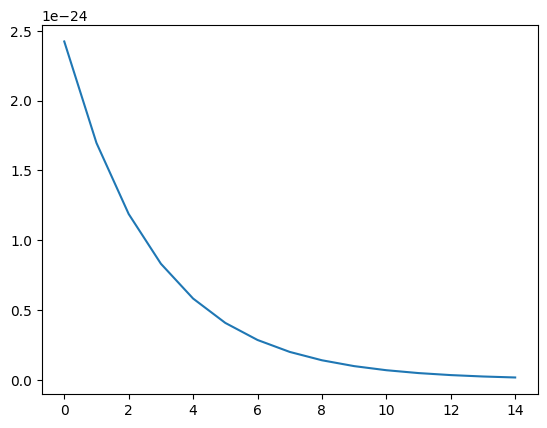

In [157]:
plt.plot(range(15),lrs);

Расписывать в этом ноутбуке все имеющиеся в PyTorch шедулеры не имеет смысла. Логику работы каждого из них можно найти [здесь](https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate).